In [2]:
import pandas as pd
import pickle

In [3]:
db = {}
with open('db.pkl', 'rb') as f:
    db = pickle.load(f)

In [4]:
for aut in db:
    db[aut] = sorted(db[aut], key=lambda val: val[1])

In [5]:
def travel_time(tz1, tz2):
    # tz = sorted([tz1, tz2])
    # match tz[0]:
    #     case -12:
    #         return 0
    #     case _:
    #         diff = abs(tz-tz1)
    #         return min(diff, abs(24-diff))
    diff = abs(tz1-tz2)
    return min(diff, abs((24*60)-diff))

In [6]:
author_flag = {}
all_diff = set()
for author in db:
    id1, ts1, tz1 = None, None, None
    for (id, ts, tz) in db[author]:
        if ts1 == None:
            id1, ts1, tz1 = id, ts, tz
            continue
        tz_diff = travel_time(tz1, tz)
        # anomalie to be clarified
        if tz_diff == 1087:
            id1, ts1, tz1 = id, ts, tz
            continue
        # if tz_diff == 720:
        #     print("swh:1:rev:"+id1)
        #     print("swh:1:rev:"+id)
        all_diff.add(tz_diff)
        if tz1 != tz:
            for max_diff in range(0, 720, 15):
                if (tz_diff > max_diff) and (tz_diff <= (max_diff+15)) and ((ts - ts1) < pd.Timedelta(minutes=tz_diff)):
                    author_flag.setdefault(max_diff, {}).setdefault(author, set()).add(("swh:1:rev:"+id1, ts1, tz1, "swh:1:rev:"+id, ts, tz))
        id1, ts1, tz1 = id, ts, tz

1m 15.9s

In [7]:
print("amount of author: ",len(set([x for tzdiff in author_flag for x in author_flag[tzdiff]])))
print("amount of flag: ",len(set([x for tzdiff in author_flag for author in author_flag[tzdiff] for x in author_flag[tzdiff][author]])))
print(sorted(all_diff))

amount of author:  3613
amount of flag:  198676
[0, 15, 30, 60, 90, 105, 120, 135, 150, 165, 180, 195, 210, 225, 240, 270, 285, 300, 330, 345, 360, 390, 420, 450, 480, 486, 510, 525, 540, 570, 585, 600, 615, 630, 645, 660, 675, 690, 705, 720]


In [8]:
import matplotlib.pyplot as plt

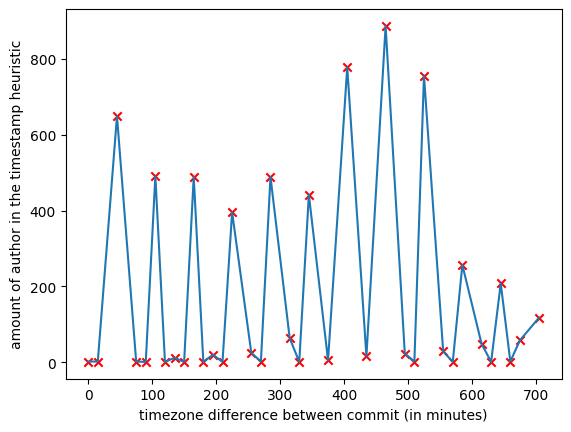

In [9]:
# amount of author per hour diff
# x = [max_diff for max_diff in range(0, 720, 60)]
x = sorted(author_flag.keys())
y = [len(author_flag[max_diff]) for max_diff in x]
plt.plot(x,y)
plt.scatter(x, y, color='red', marker='x')
plt.xlabel('timezone difference between commit (in minutes)')
plt.ylabel('amount of author in the timestamp heuristic')
plt.show()

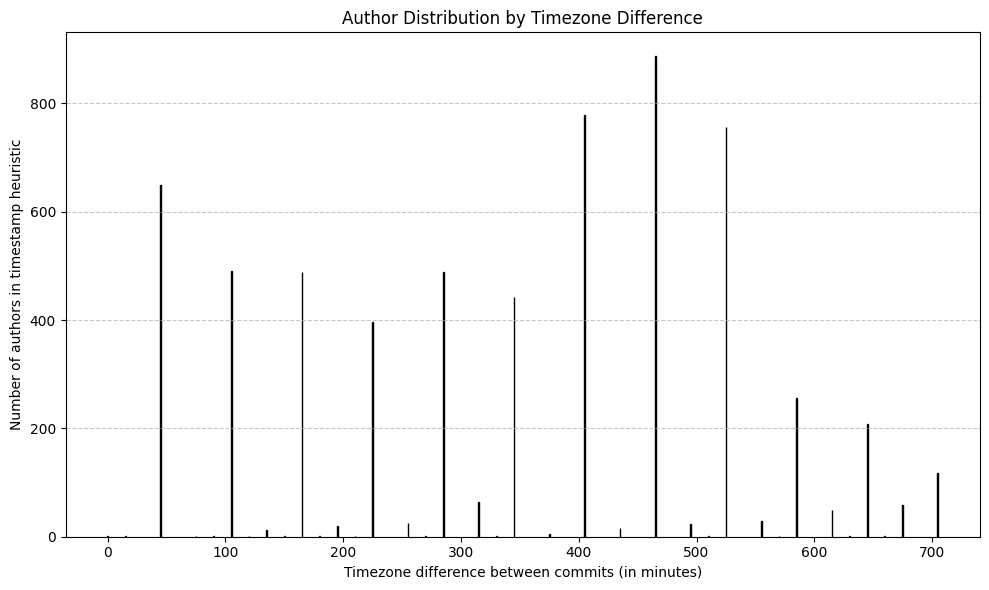

In [13]:
import numpy as np
x = sorted(author_flag.keys())
y = [len(author_flag[max_diff]) for max_diff in x]

plt.figure(figsize=(10, 6))  # Create larger figure
plt.bar(x, y, color='skyblue', edgecolor='black')  # Create bar chart

plt.xlabel('Timezone difference between commits (in minutes)')
plt.ylabel('Number of authors in timestamp heuristic')
plt.title('Author Distribution by Timezone Difference')

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

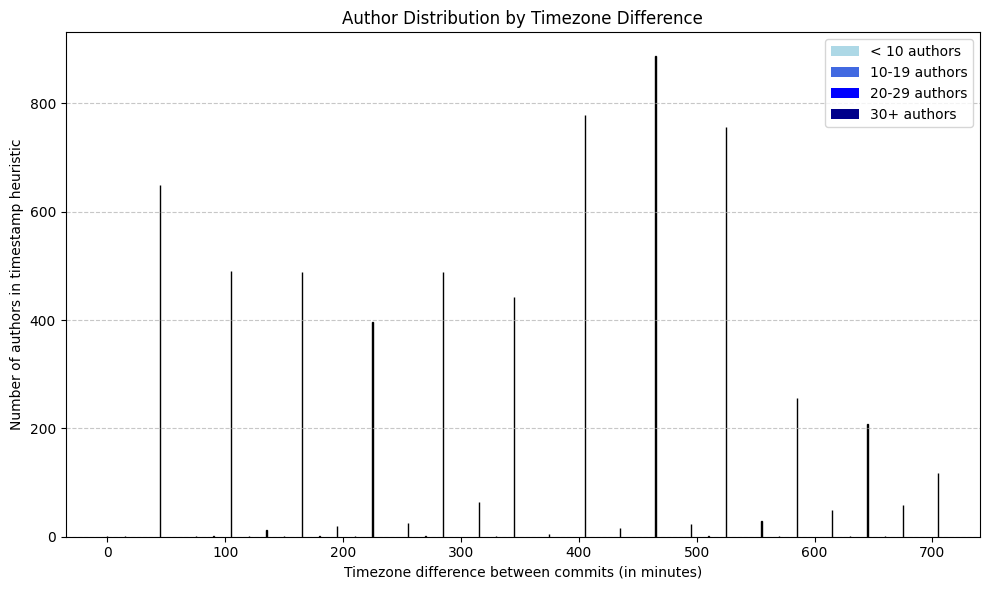

In [20]:
import matplotlib.pyplot as plt
import numpy as np

x = sorted(author_flag.keys())
y = [len(author_flag[max_diff]) for max_diff in x]

# Define color thresholds and mapping
def get_colors(values):
    colors = []
    for v in values:
        if v < 10:
            colors.append('red')
        elif v < 250:
            colors.append('green')
        else:
            colors.append('pink')
    return colors

bar_colors = get_colors(y)

plt.figure(figsize=(10, 6))
bars = plt.bar(x, y, 
               color=bar_colors,
               edgecolor='black',
               linewidth=1,
               width=0.2)

# Add color legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='lightblue', label='< 10 authors'),
    Patch(facecolor='royalblue', label='10-19 authors'),
    Patch(facecolor='blue', label='20-29 authors'),
    Patch(facecolor='darkblue', label='30+ authors')
]
plt.legend(handles=legend_elements)

plt.xlabel('Timezone difference between commits (in minutes)')
plt.ylabel('Number of authors in timestamp heuristic')
plt.title('Author Distribution by Timezone Difference')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

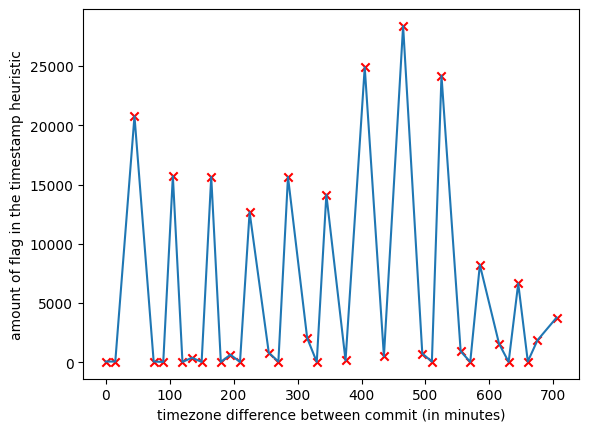

In [20]:
# amount of flag per hour diff
# x = [max_diff for max_diff in range(0, 720, 60)]
y = [len([x for author in author_flag[max_diff] for x in author]) for max_diff in x]
plt.plot(x,y)
plt.scatter(x, y, color='red', marker='x')
plt.xlabel('timezone difference between commit (in minutes)')
plt.ylabel('amount of flag in the timestamp heuristic')
plt.show()